# Polars: a DataFrame library like pandas, only faster

Polars is a DataFrame library for Python with almost the same ideas as pandas: tables, columns, filters, groups and joins. It is written in Rust, stores columns in the Apache Arrow format, uses all CPU cores and can plan a whole query before it runs it. After this block you can translate your pandas steps into Polars, run a query lazily, time pandas against Polars on the Berlin calendar, plot a Polars result, and say which other DataFrame tools exist and when they help.

## Overview

| Section | What it covers |
|---|---|
| Why Polars is fast | a short history, and the three reasons for the speed |
| From pandas to Polars | reading, no index, expressions, the verbs, groups, joins |
| Lazy queries and explain | scan_parquet, collect and the query plan |
| Timing pandas against Polars | a small benchmark on 3.76 million rows |
| Plotting with Polars | df.plot with Altair, and to_pandas() for the plotting tools of pandas |
| Other DataFrame tools | DuckDB, Dask, PySpark, Modin, cuDF and Ibis, without syntax |
| Worked example · Availability per district and month | one question, answered in Polars from the file to the chart |
| Check your understanding | four questions to vote on |
| Exercises | practice in pairs |
| Debrief | what to compare |
| Further reading | the Polars guide and the sources of the history |

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

In [2]:
import time                       # to measure how long a step takes

import pandas as pd               # pandas, to compare
import polars as pl               # Polars, by convention imported as pl

print("pandas", pd.__version__, "| polars", pl.__version__)

pandas 3.0.6 | polars 2.0.0


## Why Polars is fast

In 2017 Wes McKinney, who started pandas in 2008, wrote down what he would change in pandas. Among his points: an eager evaluation model with no query planning, and slow algorithms that use only one core. His rule of thumb was that pandas needs "5 to 10 times as much RAM as the size of your dataset" ([McKinney, 2017](https://wesmckinney.com/blog/apache-arrow-pandas-internals/)).

In 2020, at the start of the pandemic, Ritchie Vink began Polars in Rust as a pet project ([Vink, 2021](https://www.ritchievink.com/blog/2021/02/28/i-wrote-one-of-the-fastest-dataframe-libraries/)). The library reached version 1.0 on 1 July 2024 and version 2.0 on 6 October 2026; the company behind it reports over 23 million monthly users ([Polars, 2025](https://pola.rs/posts/series_a/)).

Three design choices make Polars fast:

1. **Arrow columns.** Each column is one block of typed values in memory, also for text. pandas traditionally stores text as one Python object per value.
2. **All cores.** The Rust code splits the work across the cores of the machine; most pandas operations use one core.
3. **A query plan.** In lazy mode Polars sees the whole query first and drops work it does not need, for example columns that are never used.

> **Quiz.** Which of the three would help most on a laptop with 8 cores and a 2 GB file?

## From pandas to Polars

### Reading a file and looking at it

`pl.read_parquet` reads a Parquet file into a Polars `DataFrame`, with the same idea as `pd.read_parquet`. The printout shows the shape, the type of each column under its name and `null` for a missing value.

In [3]:
listings = pl.read_parquet("case-study/data/airbnb/listings.parquet")   # one row per listing
print(listings.shape)                                                  # (rows, columns), as in pandas
listings.select("id", "district", "room_type", "price").head(3)        # select: these columns only

(10221, 42)


id,district,room_type,price
i64,str,str,f64
3176,"""Pankow""","""Entire home/apt""",160.71
9991,"""Pankow""","""Entire home/apt""",193.33
14325,"""Pankow""","""Entire home/apt""",null


In [4]:
listings.schema["price"], listings.schema["district"]   # schema: the type of each column (pandas: dtypes)

(Float64, String)

### No index in Polars

A Polars `DataFrame` has **no index**: no row labels, so no `loc` and no `iloc`. Rows are taken by position or by a condition.

**Predict.** What happens when you write `listings.loc[0]`? The next cell fails on purpose.

In [5]:
try:
    listings.loc[0]
except AttributeError as error:
    print("AttributeError:", error)

AttributeError: 'DataFrame' object has no attribute 'loc'


Read the message: the object of type `DataFrame` has no attribute `loc`. There is nothing to look up by label. The Polars ways:

In [6]:
print(listings[0, "price"])                       # row 0 by position, column by name
listings.filter(pl.col("id") == 3176)             # the row whose id is 3176: a condition, not a label

160.71


id,last_scraped,name,host_id,hosts_time_as_host_years,host_is_superhost,host_listings_count,host_identity_verified,neighbourhood,district,latitude,longitude,property_type,room_type,accommodates,bathrooms,bedrooms,beds,amenities,price,minimum_nights,maximum_nights,availability_30,availability_90,availability_365,number_of_reviews,number_of_reviews_ltm,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,calculated_host_listings_count,reviews_per_month,license_status
i64,datetime[μs],str,i64,f64,bool,f64,bool,str,str,f64,f64,str,str,i64,f64,f64,f64,str,f64,f64,f64,i64,i64,i64,i64,i64,i64,f64,datetime[μs],datetime[μs],f64,f64,f64,f64,f64,f64,f64,str,i64,f64,str
3176,2026-07-03 00:00:00,"""Fabulous Flat in great Locatio…",3718,15.0,false,1.0,true,"""Prenzlauer Berg Südwest""","""Pankow""",52.53574,13.41734,"""Entire rental unit""","""Entire home/apt""",2,null,1.0,null,"""[""Oven"", ""Board games"", ""Bakin…",160.71,2.0,730.0,8,67,342,150,1,13,2089.0,2009-06-20 00:00:00,2025-08-09 00:00:00,4.63,4.67,4.52,4.65,4.7,4.92,4.61,"""private host name""",1,0.72,"""private host name"""


### Expressions with pl.col

An **expression** describes a computation on columns without running it: `pl.col("price") * 3 + 25` is a recipe for the price of three nights with a 25 EUR cleaning fee. A **context** runs the recipe:

| Context | What it returns |
|---|---|
| `select(expr)` | only the results of the expressions |
| `with_columns(expr)` | the whole table plus the results as new columns |
| `filter(expr)` | the rows where the expression is true |
| `group_by(keys).agg(expr)` | one row per group, the expression computed per group |

In [7]:
three_nights = (pl.col("price") * 3 + 25).alias("three_nights")   # a recipe; alias names the result
three_nights                                                     # printing it shows the recipe, no numbers

<Expr ['[([(col("price")) * (dyn int: …'] at 0x11BE1AC60>

In [8]:
listings.with_columns(three_nights).select("id", "price", "three_nights").head(3)   # now it runs

id,price,three_nights
i64,f64,f64
3176,160.71,507.13
9991,193.33,604.99
14325,null,null


**Predict.** `small` below has 3 rows and 2 columns. What shape do `small.select(pl.col("price").mean())` and `small.with_columns(pl.col("price").mean().alias("mean_price"))` have?

In [9]:
small = pl.DataFrame({"district": ["Mitte", "Mitte", "Pankow"], "price": [120, 140, 40]})
print(small.select(pl.col("price").mean()).shape)                            # only the result
print(small.with_columns(pl.col("price").mean().alias("mean_price")).shape)  # the table plus the result

(1, 1)
(3, 3)


`select` keeps one value, the mean, so the shape is (1, 1). `with_columns` keeps the 3 rows and repeats the mean on each, like broadcasting in NumPy, so the shape is (3, 3).

### select, with_columns and filter

Each pandas step has a Polars method named after what it does. Every method returns a new `DataFrame`; nothing changes in place.

| pandas | Polars |
|---|---|
| `listings[["district", "price"]]` | `listings.select("district", "price")` |
| `listings[listings["price"] < 500]` | `listings.filter(pl.col("price") < 500)` |
| `listings.assign(pp=listings["price"] / 2)` | `listings.with_columns(pp=pl.col("price") / 2)` |
| `listings.sort_values("price")` | `listings.sort("price")` |
| `listings.rename(columns={"id": "listing_id"})` | `listings.rename({"id": "listing_id"})` |

In [10]:
(
    listings
    .filter(pl.col("price") < 500)                            # rows: listings under 500 EUR
    .with_columns(price_per_guest=pl.col("price") / pl.col("accommodates"))   # a new column
    .select("district", "price", "accommodates", "price_per_guest")         # these columns only
    .sort("price_per_guest", descending=True)                 # most expensive per guest first
    .head(5)
)

district,price,accommodates,price_per_guest
str,f64,i64,f64
"""Mitte""",322.04,1,322.04
"""Friedrichshain-Kreuzberg""",300.0,1,300.0
"""Pankow""",276.92,1,276.92
"""Charlottenburg-Wilm.""",250.0,1,250.0
"""Friedrichshain-Kreuzberg""",497.0,2,248.5


### group_by and agg

`group_by(keys)` splits the rows; `agg(...)` takes one expression per summary. `pl.len()` counts the rows of each group, like `size` in pandas. Polars computes the groups in parallel and returns them **in any order**, so sort the result.

**Predict.** Which district has the lowest median price? You met the answer in the pandas deck.

In [11]:
(
    listings
    .group_by("district")
    .agg(pl.len().alias("n"),                                  # rows per district
         pl.col("price").median().alias("median_price"))       # median price per district
    .sort("median_price")                                      # cheapest first; without sort the order changes
    .head(5)
)

district,n,median_price
str,u32,f64
"""Reinickendorf""",141,81.25
"""Marzahn - Hellersdorf""",95,96.0
"""Steglitz - Zehlendorf""",285,103.0
"""Treptow - Köpenick""",459,108.25
"""Charlottenburg-Wilm.""",1146,112.5


### Joining tables

`join` is a method of the left table: `left.join(right, on=..., how=...)`, or `left_on=` and `right_on=` when the key has two names. The kinds of join are those of `pd.merge`: `"inner"` (default), `"left"`, `"right"`, and `"full"`, which pandas calls `"outer"`.

In [12]:
calendar = pl.read_parquet("case-study/data/airbnb/calendar.parquet")   # one row per listing and day
calendar_with_district = calendar.join(
    listings.select("id", "district"),        # only the two columns we need from listings
    left_on="listing_id", right_on="id",      # the key has a different name in each table
    how="left",                               # keep every calendar row
)
print(calendar.shape, calendar_with_district.shape)
calendar_with_district.head(3)

(3759500, 4) (3759500, 5)


listing_id,date,available,minimum_nights,district
i64,datetime[μs],bool,i64,str
3176,2026-07-03 00:00:00,false,63,"""Pankow"""
3176,2026-07-04 00:00:00,false,63,"""Pankow"""
3176,2026-07-05 00:00:00,false,63,"""Pankow"""


**Predict.** Some calendar rows belong to listings that are not in the listings table. After a group-by on `district`, does Polars keep them, and does pandas?

In [13]:
groups_polars = calendar_with_district.group_by("district").agg(pl.col("available").mean())
groups_pandas = calendar_with_district.to_pandas().groupby("district")["available"].mean()
print("Polars groups:", groups_polars.height, "| pandas groups:", len(groups_pandas))
groups_polars.filter(pl.col("district").is_null())     # the group without a district

Polars groups: 13 | pandas groups: 12


district,available
str,f64
null,0.766152


Polars keeps a missing key as a group of its own, `null`; pandas `groupby` drops it unless you pass `dropna=False`. The same question can give one more row in Polars: check missing keys before you compare results.

## Lazy queries and explain

`pl.scan_parquet` does not read the file. It returns a `LazyFrame` that records the steps; `collect()` runs them. Before running, Polars optimises the plan: it reads only the columns the query needs (projection pushdown) and applies filters while reading (predicate pushdown). `explain()` prints the optimised plan.

In [14]:
query = (
    pl.scan_parquet("case-study/data/airbnb/calendar.parquet")   # nothing is read yet
    .filter(pl.col("minimum_nights") <= 3)                       # short stays only
    .group_by("listing_id")
    .agg(pl.col("available").mean().alias("share_available"))
)
print(query.explain())       # read from the bottom: the scan, then the steps above it

AGGREGATE[maintain_order: false]
  [col("available").mean().alias("share_available")] BY [col("listing_id")]
  FROM
  simple π 2/2 ["listing_id", "available"]
    Parquet SCAN [case-study/data/airbnb/calendar.parquet]
    PROJECT 3/4 COLUMNS
    SELECTION: col("minimum_nights") <= 3
    ESTIMATED ROWS: 3759500


Read the plan from the bottom: `PROJECT 3/4 COLUMNS` means only 3 of the 4 columns are read, and `SELECTION` shows the filter running inside the scan. Then `collect()` runs it:

In [15]:
result = query.collect()     # now the file is read and the plan runs
result.sort("share_available", descending=True).head(3)

listing_id,share_available
i64,f64
1111366155764122467,1.0
7495407,1.0
17508652,1.0


A DataFrame you already have becomes lazy with `.lazy()`: `listings.lazy().filter(...).collect()`.

## Timing pandas against Polars

A benchmark only holds for its data, its machine and its versions, so measure on yours. `time.perf_counter()` reads a clock; the difference between two readings is the time a step took. We take the median of five runs after one warm-up run.

**Predict.** On 3.76 million calendar rows, how many times faster will Polars be for a join and a group-by: 2, 10 or 100?

In [16]:
import statistics

def median_seconds(step, runs=5):
    """Run step once to warm up, then return the median time of `runs` runs in seconds."""
    step()
    times = []
    for _ in range(runs):
        start = time.perf_counter()
        step()
        times.append(time.perf_counter() - start)
    return statistics.median(times)

calendar_pd = calendar.to_pandas()                   # the same data as a pandas table
listings_pd = listings.to_pandas()

In [17]:
def with_pandas():
    merged = calendar_pd.merge(listings_pd[["id", "district"]], left_on="listing_id", right_on="id", how="left")
    return merged.groupby("district")["available"].mean()

def with_polars():
    return (calendar.join(listings.select("id", "district"), left_on="listing_id", right_on="id", how="left")
            .group_by("district").agg(pl.col("available").mean()))

seconds_pandas, seconds_polars = median_seconds(with_pandas), median_seconds(with_polars)
print(f"pandas {seconds_pandas * 1000:.0f} ms | Polars {seconds_polars * 1000:.0f} ms | "
      f"{seconds_pandas / seconds_polars:.1f} times faster")

pandas 76 ms | Polars 21 ms | 3.5 times faster


Your numbers depend on your laptop and on the query. The deck shows the lecturer's measurements on an Apple M5 Pro with 18 cores: Polars was 1.4 to 4 times faster than pandas 3, depending on the step, and lazy mode added much more. The Polars team's own benchmark reports much larger factors on a 96-core server and 10 GB of tables ([Polars, 2025](https://pola.rs/posts/benchmarks/)).

Now a small table: the 10,221 listings.

In [18]:
seconds_pandas = median_seconds(lambda: listings_pd.groupby("district")["price"].median())
seconds_polars = median_seconds(lambda: listings.group_by("district").agg(pl.col("price").median()))
print(f"pandas {seconds_pandas * 1000:.2f} ms | Polars {seconds_polars * 1000:.2f} ms")

pandas 0.51 ms | Polars 0.61 ms


On ten thousand rows both take well under a millisecond, and pandas can even be faster: there is too little work to share across cores. Speed matters when a step takes seconds or minutes.

## Plotting with Polars

### df.plot with Altair

A Polars `DataFrame` has `df.plot.kind(x=..., y=...)`, the same generic call as in pandas, but it draws with **Altair**, not matplotlib. The result is an interactive chart: hover over a bar to see its value. The plotting deck covers charts in depth; here only the call.

In [19]:
by_district = listings.group_by("district").agg(pl.len().alias("n"))   # one row per district
by_district.plot.bar(x="n", y="district")                              # an Altair bar chart

alt.Chart(...)

Altair copies the data into the chart, so by default it refuses tables of more than 5,000 rows. The map has 6,022 listings. **Predict.** What happens? The next cell fails on purpose.

In [20]:
import altair as alt   # the library behind df.plot in Polars

cheap = listings.filter(pl.col("price") < 300)                 # 6,022 listings under 300 EUR
try:
    cheap.plot.point(x="longitude", y="latitude", color="price").to_dict()   # to_dict builds the chart
except alt.MaxRowsError as error:
    print("MaxRowsError:", str(error).splitlines()[0])

MaxRowsError: The number of rows in your dataset (6022) is greater than the maximum allowed (5000).


Read the message: the dataset has more rows than the maximum allowed, 5,000. Keep only the columns you plot, so the chart stays small, and lift the limit for this notebook.

In [21]:
alt.data_transformers.disable_max_rows()                       # allow more than 5,000 rows
(cheap.select("longitude", "latitude", "price")                # only the three plotted columns
 .plot.point(x=alt.X("longitude", scale=alt.Scale(zero=False)),   # zero=False: do not start the axis at 0
             y=alt.Y("latitude", scale=alt.Scale(zero=False)),
             color="price"))

alt.Chart(...)

### to_pandas for matplotlib and seaborn

For the matplotlib charts of the plotting deck, reduce the data in Polars, convert the small result with `to_pandas()`, and plot it with pandas. Some libraries do not accept a Polars table: seaborn 0.13.2 raises a `TypeError`, shown on purpose in the next cell.

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

top = listings.group_by("district").agg(pl.col("price").median()).sort("price")   # 12 rows
try:
    sns.barplot(data=top, x="price", y="district")             # a Polars table
except TypeError as error:
    print("TypeError:", error)
plt.close("all")

TypeError: Data source must be a DataFrame or Mapping, not <class 'polars.dataframe.frame.DataFrame'>.


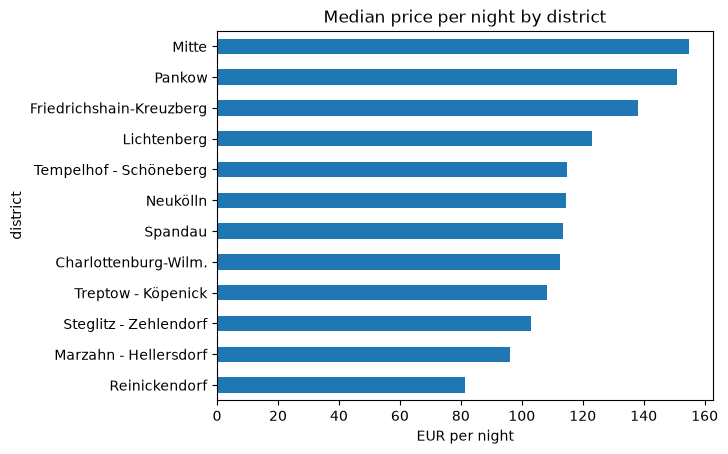

In [23]:
top.to_pandas().plot.barh(x="district", y="price", legend=False,      # the pandas plotting tools
                          title="Median price per night by district", xlabel="EUR per night")
plt.show()

## Other DataFrame tools

You do not need the syntax of these tools now, but you will meet their names in job advertisements and in projects. Each removes a different limit of pandas.

| Tool | What it is | Pick it when |
|---|---|---|
| [DuckDB](https://duckdb.org/docs/stable/) | an in-process SQL database for analytics; SQL on Parquet and CSV files and on pandas or Polars tables | your team thinks in SQL; files of many GB on one laptop |
| [pandas with Arrow](https://pandas.pydata.org/docs/whatsnew/v3.0.0.html) | pandas 3.0 stores text as Arrow strings by default; all columns can use Arrow types | the code is pandas and should stay pandas |
| [Dask](https://docs.dask.org/en/stable/dataframe.html) | splits a pandas DataFrame into partitions and runs them in parallel, on all cores or a cluster | data larger than memory, pandas code |
| [PySpark](https://spark.apache.org/docs/latest/api/python/) | the Python interface of Apache Spark, a distributed engine for clusters | data spread over many machines |
| [Modin](https://modin.readthedocs.io/) | runs pandas code in parallel after changing one import | a quick speed-up without rewriting |
| [cuDF (RAPIDS)](https://docs.rapids.ai/api/cudf/stable/) | DataFrames on an NVIDIA graphics card; can also run pandas code there | a GPU is available and the data is large |
| [Ibis](https://ibis-project.org/) | one Python DataFrame API that writes queries for many engines | the engine may change later |

Choose by the size of the data and the waiting time: pandas or Polars on one machine first; lazy or streaming mode, SQL, a cluster or a GPU only when the data asks for it.

## Worked example · Availability per district and month

**Question.** In which months of the calendar are listings in Mitte and in Neukölln most often still available?

### Step 1 · Build the query lazily

**Why this step?** Writing the whole question as one lazy query lets Polars read only the needed columns of the calendar and filter the two districts before the group-by.

In [24]:
availability = (
    pl.scan_parquet("case-study/data/airbnb/calendar.parquet")
    .join(pl.scan_parquet("case-study/data/airbnb/listings.parquet").select("id", "district"),
          left_on="listing_id", right_on="id", how="inner")       # keep calendar rows with a known district
    .filter(pl.col("district").is_in(["Mitte", "Neukölln"]))      # the two districts of the question
    .group_by("district", pl.col("date").dt.month().alias("month"))
    .agg(pl.col("available").mean().alias("share_available"))
    .sort("district", "month")                                    # a fixed order for reading and plotting
)

### Step 2 · Run it and read the table

In [25]:
availability_table = availability.collect()
availability_table.head(6)

district,month,share_available
str,i8,f64
"""Mitte""",1,0.507311
"""Mitte""",2,0.496268
"""Mitte""",3,0.487185
"""Mitte""",4,0.421223
"""Mitte""",5,0.424376
"""Mitte""",6,0.376396


### Step 3 · Plot the two lines

What do you see? Read the chart before the next cell interprets it.

In [26]:
availability_table.plot.line(x="month", y="share_available", color="district")   # one line per district

alt.Chart(...)

In both districts more days are still available from October to March than from April to September, and Neukölln is less often available than Mitte in every month. An unavailable day can be booked or blocked by the host, so read it as demand only with care. One more caveat: the calendar runs from 26 June 2026 to 2 July 2027, so the months June and July mix days of two years.

## Check your understanding

Vote alone first, then discuss with your neighbour, then vote again.

1. In Polars, `listings.loc[0]` gives: **A** the row with label 0 · **B** the first row · **C** an AttributeError · **D** the first column
2. `small` has 3 rows. `small.select(pl.col("price").mean())` has which shape? **A** (1, 1) · **B** (3, 1) · **C** (3, 2) · **D** (1, 2)
3. A Polars `group_by` result comes back: **A** sorted by the key · **B** in the order of the first appearance · **C** in any order, so sort it · **D** sorted by the value
4. On 10,000 rows, which is true? **A** Polars is always 10 times faster · **B** both are fast; pandas can win · **C** Polars needs lazy mode · **D** pandas fails

## Exercises

Work in pairs; the lecturer picks which exercises to set.

### 6.1 · The pandas questions in Polars

*Code*

> Answer in Polars: How many listings and how many hosts are there? How many listings has each room type? What is the median price per room type? Sort every result.

*Source: course exercise.*

### 6.2 · Reviews per year

*Code*

> From `case-study/data/airbnb/reviews_monthly.parquet`, compute the number of reviews per year with a lazy query (`scan_parquet`, `group_by` on `pl.col("month").dt.year()`, `collect`). Print the plan with `explain()` first.

*Source: course exercise.*

### 6.3 · Your own benchmark

*Pairs*

> Time one pandas step of your choice from notebook 03 against its Polars version, on the calendar and on the listings, with `median_seconds`. Write one sentence on what you found and on which machine.

*Source: course exercise.*

### 6.4 · Translate the chain

*Code*

> Translate this pandas chain into Polars:
>
> ```python
> (listings_pd[listings_pd["room_type"] == "Entire home/apt"]
>  .assign(price_per_guest=lambda df: df["price"] / df["accommodates"])
>  .groupby("district")["price_per_guest"].median()
>  .sort_values())
> ```

*Source: course exercise.*

### 6.5 · *Stretch:* A chart from a lazy query

*Code*

> Build one lazy query that gives the number of available short-stay days (minimum_nights at most 3) per district, then draw it with `df.plot.bar`.

*Source: course exercise.*

## Debrief

- Compare two answers to 6.1: one with `sort`, one without. Run the unsorted one twice: the order of the rows can change.
- In 6.3, collect the factors of the class on the board: they differ by laptop and by step, and that is the point of measuring.
- In 6.4, look for `loc` or square-bracket masks left over from pandas.

## Further reading

- Polars development team, [Polars user guide](https://docs.pola.rs/user-guide/) and [Coming from pandas](https://docs.pola.rs/user-guide/migration/pandas/).
- McKinney, 2017, [Apache Arrow and the "10 Things I Hate About pandas"](https://wesmckinney.com/blog/apache-arrow-pandas-internals/).
- Vink, 2021, [I wrote one of the fastest DataFrame libraries](https://www.ritchievink.com/blog/2021/02/28/i-wrote-one-of-the-fastest-dataframe-libraries/).
- Polars, 2025, [Updated PDS-H benchmark results (May 2025)](https://pola.rs/posts/benchmarks/): the vendor's benchmark, with its setup.